# FinanceRAG — Notebook d'Exploration

**Objectif** : Tester le pipeline RAG de bout en bout, évaluer la qualité du retrieval et des réponses.

---
**Sections :**
1. Setup & Configuration
2. Chargement et inspection des documents
3. Découpage en chunks (analyse)
4. Test du retrieval (pertinence)
5. Test du pipeline RAG complet
6. Évaluation qualitative

In [1]:
# ── Setup ──────────────────────────────────────────────────────────────
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# FinanceRAG
from src.config import CHUNK_SIZE, CHUNK_OVERLAP, EMBEDDING_MODEL
from src.document_loader import load_directory, get_document_stats
from src.indexing import split_documents, build_vectorstore
from src.retriever import FinanceRetriever

print('✓ Imports OK')
print(f'  Chunk size: {CHUNK_SIZE} | Overlap: {CHUNK_OVERLAP}')
print(f'  Embedding: {EMBEDDING_MODEL}')

2026-10-19 00:30:40.045 | INFO     | src.config:<module>:72 - Config chargée — modèle : claude-haiku-5-5 | chunks : 800/100


✓ Imports OK
  Chunk size: 800 | Overlap: 100
  Embedding: sentence-transformers/all-MiniLM-L6-v2


In [2]:
import os

src_dir = r"C:\Users\asus\Desktop\FinanceRAG\src"

replacements = {
    "from langchain.schema import Document": "from langchain_core.documents import Document",
    "from langchain.text_splitter import": "from langchain_text_splitters import",
    "from langchain.schema import": "from langchain_core.documents import",
}

for filename in os.listdir(src_dir):
    if filename.endswith(".py"):
        filepath = os.path.join(src_dir, filename)
        with open(filepath, "r", encoding="utf-8") as f:
            content = f.read()
        
        new_content = content
        for old, new in replacements.items():
            new_content = new_content.replace(old, new)
        
        if new_content != content:
            with open(filepath, "w", encoding="utf-8") as f:
                f.write(new_content)
            print(f"✅ Corrigé : {filename}")
        else:
            print(f"⏭️ Pas de changement : {filename}")

⏭️ Pas de changement : config.py
⏭️ Pas de changement : document_loader.py
⏭️ Pas de changement : indexing.py
⏭️ Pas de changement : rag_pipeline.py
⏭️ Pas de changement : retriever.py
⏭️ Pas de changement : __init__.py


## 1. Chargement des documents

In [3]:
# Charger tous les documents du répertoire data/raw
docs = load_directory('../data/raw')
stats = get_document_stats(docs)

print(f"📄 Documents chargés :")
print(f"  - Fichiers sources  : {stats['nb_documents']}")
print(f"  - Segments totaux   : {stats['nb_segments']}")
print(f"  - Caractères moyens : {stats['avg_chars']:,}")
print(f"  - Caractères totaux : {stats['total_chars']:,}")
print()
print('Sources :')
for s in stats['sources']:
    print(f'  • {s}')

2026-10-19 00:30:45.860 | INFO     | src.document_loader:load_directory:108 - Chargement de 3 fichier(s) depuis raw/
2026-10-19 00:30:45.863 | INFO     | src.document_loader:load_document:49 - Chargement : exemple_conditions_assurance.txt (.txt)
2026-10-19 00:30:45.866 | SUCCESS  | src.document_loader:load_document:82 - ✓ exemple_conditions_assurance.txt → 1 segment(s) chargé(s)
2026-10-19 00:30:45.869 | INFO     | src.document_loader:load_document:49 - Chargement : exemple_rapport_annuel.txt (.txt)
2026-10-19 00:30:45.871 | SUCCESS  | src.document_loader:load_document:82 - ✓ exemple_rapport_annuel.txt → 1 segment(s) chargé(s)
2026-10-19 00:30:45.874 | INFO     | src.document_loader:load_document:49 - Chargement : exemple_reglement_credit.txt (.txt)
2026-10-19 00:30:45.878 | SUCCESS  | src.document_loader:load_document:82 - ✓ exemple_reglement_credit.txt → 1 segment(s) chargé(s)
2026-10-19 00:30:45.879 | SUCCESS  | src.document_loader:load_directory:117 - ✓ Total : 3 segments depuis 3 

📄 Documents chargés :
  - Fichiers sources  : 3
  - Segments totaux   : 3
  - Caractères moyens : 3,378
  - Caractères totaux : 10,133

Sources :
  • exemple_conditions_assurance.txt
  • exemple_rapport_annuel.txt
  • exemple_reglement_credit.txt


In [4]:
# Inspecter un document
if docs:
    doc = docs[0]
    print(f"Source : {doc.metadata['source']}")
    print(f"Page   : {doc.metadata.get('page', 'N/A')}")
    print(f"Chars  : {len(doc.page_content)}")
    print()
    print("Extrait (200 premiers caractères) :")
    print("-" * 50)
    print(doc.page_content[:200])

Source : exemple_conditions_assurance.txt
Page   : N/A
Chars  : 3522

Extrait (200 premiers caractères) :
--------------------------------------------------
CONDITIONS GÉNÉRALES — ASSURANCE VIE "PATRIMOINE PLUS"
Référence : AV-PATR-2024-001 | Version : 3.2 | Date d'effet : 01/01/2024

ARTICLE 1 — OBJ


## 2. Analyse du Découpage (Chunking)

2026-10-19 00:30:45.922 | INFO     | src.indexing:split_documents:73 - Découpage : 3 segment(s) → 15 chunk(s)
2026-10-19 00:30:45.923 | INFO     | src.indexing:split_documents:74 -   Taille moyenne : 680 chars/chunk


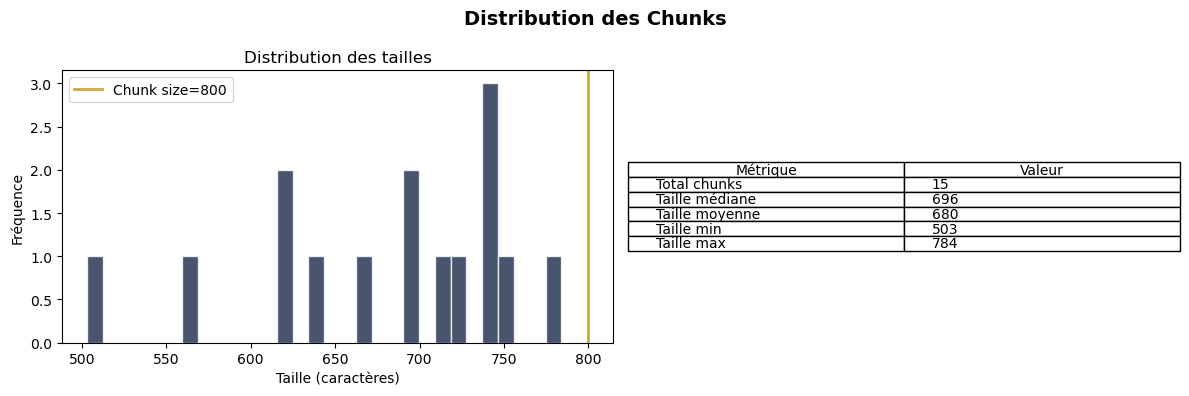

✓ 15 chunks générés


In [5]:
# Découper les documents
chunks = split_documents(docs)

# Distribution des tailles de chunks
chunk_sizes = [len(c.page_content) for c in chunks]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Distribution des Chunks', fontsize=14, fontweight='bold')

# Histogramme
axes[0].hist(chunk_sizes, bins=30, color='#1B2A4A', alpha=0.8, edgecolor='white')
axes[0].axvline(CHUNK_SIZE, color='#C9A84C', linewidth=2, label=f'Chunk size={CHUNK_SIZE}')
axes[0].set_xlabel('Taille (caractères)')
axes[0].set_ylabel('Fréquence')
axes[0].set_title('Distribution des tailles')
axes[0].legend()

# Statistiques
import numpy as np
stats_data = {
    'Métrique': ['Total chunks', 'Taille médiane', 'Taille moyenne', 'Taille min', 'Taille max'],
    'Valeur': [len(chunks), int(np.median(chunk_sizes)), int(np.mean(chunk_sizes)), 
               min(chunk_sizes), max(chunk_sizes)]
}
df_stats = pd.DataFrame(stats_data)
axes[1].axis('off')
table = axes[1].table(cellText=df_stats.values, colLabels=df_stats.columns, 
                      loc='center', cellLoc='left')
table.auto_set_font_size(True)

plt.tight_layout()
plt.savefig('../docs/chunk_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ {len(chunks)} chunks générés')

## 3. Test du Retrieval

In [6]:
# Construire l'index (sans sauvegarder) pour tester
print('Construction de l\'index FAISS (peut prendre 1-2 min)...')
vectorstore = build_vectorstore(chunks, save_path='../vectorstore/faiss_index')
retriever = FinanceRetriever(vectorstore, top_k=3)
print('✓ Index construit')

2026-10-19 00:30:46.826 | INFO     | src.indexing:build_vectorstore:98 - Chargement du modèle d'embedding : sentence-transformers/all-MiniLM-L6-v2


Construction de l'index FAISS (peut prendre 1-2 min)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-19 00:32:32.592 | INFO     | src.indexing:build_vectorstore:106 - Génération des embeddings pour 15 chunks...
2026-10-19 00:32:32.594 | INFO     | src.indexing:build_vectorstore:112 - Construction de l'index FAISS...
2026-10-19 00:32:33.876 | SUCCESS  | src.indexing:build_vectorstore:119 - ✓ Index FAISS construit — 15 vecteurs
2026-10-19 00:32:33.881 | SUCCESS  | src.indexing:build_vectorstore:124 - ✓ Index sauvegardé : ../vectorstore/faiss_index
2026-10-19 00:32:33.883 | INFO     | src.retriever:__init__:43 - Retriever initialisé — stratégie : similarity | top_k : 3 | seuil : 0.3


✓ Index construit


In [7]:
# Tester plusieurs requêtes
test_queries = [
    "Quels sont les frais de gestion ?",
    "Quelle est la garantie décès ?",
    "Comment calculer le taux d'intérêt ?",
    "Quels sont les critères d'éligibilité ?",
]

for query in test_queries:
    print(f"\n🔍 '{query}'")
    print("-" * 60)
    retrieved = retriever.retrieve(query)
    for i, doc in enumerate(retrieved, 1):
        score = doc.metadata.get('similarity_score', 'N/A')
        source = doc.metadata.get('source', '?')
        preview = doc.page_content[:100].replace('\n', ' ')
        print(f"  [{i}] {source} | score={score}")
        print(f"      {preview}...")

2026-10-19 00:32:33.903 | INFO     | src.retriever:retrieve:67 - Requête : 'Quels sont les frais de gestion ?'
2026-10-19 00:32:33.932 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.475
2026-10-19 00:32:33.933 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_rapport_annuel.txt score=0.442
2026-10-19 00:32:33.934 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.440
2026-10-19 00:32:33.936 | INFO     | src.retriever:retrieve:111 - → 3 chunk(s) pertinent(s) trouvé(s)
2026-10-19 00:32:33.938 | INFO     | src.retriever:retrieve:67 - Requête : 'Quelle est la garantie décès ?'
2026-10-19 00:32:33.975 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.478
2026-10-19 00:32:33.976 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.469
2026-10-19 00:32:33.977 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_reglement_credit.txt score=0.463


🔍 'Quels sont les frais de gestion ?'
------------------------------------------------------------
  [1] exemple_conditions_assurance.txt | score=0.47450000047683716
      2.2 Frais de gestion annuels - Support en euros (fonds garanti) : 0,75% par an - Supports en unités ...
  [2] exemple_rapport_annuel.txt | score=0.44190001487731934
      3. GESTION DES RISQUES  Coût du risque Le coût du risque s'établit à 35 points de base des encours d...
  [3] exemple_conditions_assurance.txt | score=0.4397999942302704
      Au-delà de cet abattement, les plus-values sont soumises au Prélèvement Forfaitaire Libératoire (PFL...

🔍 'Quelle est la garantie décès ?'
------------------------------------------------------------
  [1] exemple_conditions_assurance.txt | score=0.478300005197525
      2.2 Frais de gestion annuels - Support en euros (fonds garanti) : 0,75% par an - Supports en unités ...
  [2] exemple_conditions_assurance.txt | score=0.4690000116825104
      3.2 Garantie Décès En cas de déc

## 4. Pipeline RAG Complet

In [8]:
# ⚠️ Nécessite ANTHROPIC_API_KEY dans .env
from src.rag_pipeline import FinanceRAGPipeline

pipeline = FinanceRAGPipeline()

question = "Quels sont les frais de gestion annuels de l'assurance vie ?"
response = pipeline.query(question)

print(f"Question : {question}")
print("=" * 60)
print(f"Réponse :\n{response.answer}")
print("=" * 60)
print(f"Sources : {', '.join(response.sources)}")
print(f"Tokens  : {response.total_tokens} (in={response.input_tokens}, out={response.output_tokens})")

2026-10-19 00:32:34.174 | INFO     | src.indexing:load_vectorstore:150 - Chargement de l'index FAISS : C:\Users\asus\Desktop\FinanceRAG\vectorstore\faiss_index


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-19 00:32:36.247 | SUCCESS  | src.indexing:load_vectorstore:163 - ✓ Index FAISS chargé depuis C:\Users\asus\Desktop\FinanceRAG\vectorstore\faiss_index
2026-10-19 00:32:36.248 | INFO     | src.retriever:__init__:43 - Retriever initialisé — stratégie : similarity | top_k : 5 | seuil : 0.3
2026-10-19 00:32:36.249 | SUCCESS  | src.rag_pipeline:__init__:120 - FinanceRAGPipeline initialisé ✓
2026-10-19 00:32:36.252 | INFO     | src.rag_pipeline:query:137 - Question reçue : Quels sont les frais de gestion annuels de l'assurance vie ?
2026-10-19 00:32:36.254 | INFO     | src.retriever:retrieve:67 - Requête : 'Quels sont les frais de gestion annuels de l'assurance vie ?'
2026-10-19 00:32:36.296 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.542
2026-10-19 00:32:36.298 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.500
2026-10-19 00:32:36.300 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_reglement_cred

Question : Quels sont les frais de gestion annuels de l'assurance vie ?
Réponse :
Les frais de gestion annuels de l'assurance vie « Patrimoine Plus » sont les suivants :

- Support en euros (fonds garanti) : 0,75 % par an
- Supports en unités de compte actions : 0,90 % par an
- Supports immobiliers (SCPI, OPCI) : 1,20 % par an

Ces frais sont prélevés chaque trimestre sur la valeur de l'épargne constituée.

Sources :
- [Source: exemple_conditions_assurance.txt — Article 2.2 « Frais de gestion annuels » (pertinence : 48 %)]
Sources : exemple_conditions_assurance.txt, exemple_reglement_credit.txt
Tokens  : 2295 (in=2088, out=207)


## 5. Évaluation qualitative

| Critère | Description | Score (1-5) |
|---------|-------------|-------------|
| Pertinence du retrieval | Les chunks récupérés sont-ils pertinents ? | — |
| Fidélité | La réponse est-elle fidèle aux sources ? | — |
| Citation des sources | Les sources sont-elles bien citées ? | — |
| Refus hors-sujet | Répond-il "Je ne sais pas" quand il le faut ? | — |
| Qualité du français | La réponse est-elle fluide et précise ? | — |

In [9]:
# Test de refus : question hors-sujet
response_hors_sujet = pipeline.query("Quel est le temps qu'il fait à Paris aujourd'hui ?")
print("Question hors-sujet :")
print(response_hors_sujet.answer)
# Attendu : message indiquant que l'information n'est pas dans les documents

2026-10-19 00:32:43.014 | INFO     | src.rag_pipeline:query:137 - Question reçue : Quel est le temps qu'il fait à Paris aujourd'hui ?
2026-10-19 00:32:43.016 | INFO     | src.retriever:retrieve:67 - Requête : 'Quel est le temps qu'il fait à Paris aujourd'hui ?'
2026-10-19 00:32:43.097 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_reglement_credit.txt score=0.443
2026-10-19 00:32:43.098 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.431
2026-10-19 00:32:43.099 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.429
2026-10-19 00:32:43.102 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_conditions_assurance.txt score=0.427
2026-10-19 00:32:43.105 | DEBUG    | src.retriever:retrieve:101 -   ✓ exemple_reglement_credit.txt score=0.425
2026-10-19 00:32:43.107 | INFO     | src.retriever:retrieve:111 - → 5 chunk(s) pertinent(s) trouvé(s)
2026-10-19 00:32:43.110 | INFO     | src.rag_pipeline:query:168 - App

Question hors-sujet :
Je ne trouve pas cette information dans les documents disponibles.

Les extraits fournis portent sur le crédit immobilier (caractéristiques du bien, calcul du taux, TAEG, assurance emprunteur) et sur l'assurance vie « Patrimoine Plus » (frais, rachats, fiscalité, garantie décès). Aucun ne contient de données météorologiques.

Pour obtenir la météo de Paris, il faut consulter un service météorologique officiel (par exemple Météo-France) ou une source d'information en temps réel.

Sources : aucune source pertinente dans le contexte fourni.
